In [1]:
# %matplotlib inline

In [2]:
#  Imports
import os, json
import torch
import torch.nn as nn
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, random_split
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report
import matplotlib.pyplot as plt
from tqdm import tqdm
import numpy as np

In [3]:
#  Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [4]:
#  Paths
train_path = r"C:\Users\STUDENT\Downloads\brainmri\archive\Training_256x256"
test_path  = r"C:\\Users\\STUDENT\\Downloads\\brainmri\\archive\\Testing_256x256"

In [5]:
#  Transforms
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])
test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

In [6]:
#  Dataset + Dataloaders
full_dataset = datasets.ImageFolder(root=train_path, transform=train_transform)
train_size = int(0.7 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])
val_dataset.dataset.transform = test_transform

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=2, pin_memory=True)


In [7]:
#  Model: DenseNet121
model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)
model.classifier = nn.Sequential(
    nn.Dropout(0.4),
    nn.Linear(model.classifier.in_features, 4)
)
model.to(device)

DenseNet(
  (features): Sequential(
    (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu0): ReLU(inplace=True)
    (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (denseblock1): _DenseBlock(
      (denselayer1): _DenseLayer(
        (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu1): ReLU(inplace=True)
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu2): ReLU(inplace=True)
        (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (denselayer2): _DenseLayer(
        (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu

In [8]:
#  Training Setup
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)

In [9]:
#  Tracking
train_accuracies, val_accuracies = [], []
train_losses, val_losses = [], []
all_preds, all_labels = [], []


In [10]:
#  Training Loop
best_val_acc = 0
best_model = model.state_dict()
patience, counter = 3, 0

for epoch in range(10):
    print(f"\n\033[95mEpoch {epoch+1}/10\033[0m")
    model.train()
    correct, total, running_loss = 0, 0, 0.0

    for imgs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1} [Train]", leave=False):
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)
        running_loss += loss.item()

    train_acc = 100 * correct / total
    train_accuracies.append(train_acc)
    train_losses.append(running_loss / len(train_loader))

    #  Validation
    model.eval()
    correct, total, val_loss = 0, 0, 0.0
    all_preds_fold, all_labels_fold = [], []

    with torch.no_grad():
        for imgs, labels in tqdm(val_loader, desc=f"Epoch {epoch+1} [Val]", leave=False):
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            val_loss += loss.item()
            all_preds_fold.extend(preds.cpu().numpy())
            all_labels_fold.extend(labels.cpu().numpy())

    val_acc = 100 * correct / total
    val_accuracies.append(val_acc)
    val_losses.append(val_loss / len(val_loader))

    print(f"→ Train Acc: {train_acc:.2f}%, Val Acc: {val_acc:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_model = model.state_dict()
        all_preds = all_preds_fold
        all_labels = all_labels_fold
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print(" Early stopping triggered.")
            break

    scheduler.step()



Epoch 1/10


→ Train Acc: 88.57%, Val Acc: 96.32%

Epoch 2/10


→ Train Acc: 96.92%, Val Acc: 97.90%

Epoch 3/10


→ Train Acc: 98.22%, Val Acc: 97.55%

Epoch 4/10


→ Train Acc: 98.82%, Val Acc: 98.31%

Epoch 5/10


...

→ Train Acc: 99.62%, Val Acc: 98.77%

Epoch 7/10


→ Train Acc: 99.90%, Val Acc: 98.95%

Epoch 8/10


→ Train Acc: 99.97%, Val Acc: 98.95%

Epoch 9/10


→ Train Acc: 99.97%, Val Acc: 99.07%

Epoch 10/10


→ Train Acc: 99.92%, Val Acc: 99.07%


In [11]:
#  Load Best Model
model.load_state_dict(best_model)

<All keys matched successfully>

In [12]:
#  Metrics
precision = precision_score(all_labels, all_preds, average='macro')
recall = recall_score(all_labels, all_preds, average='macro')
f1 = f1_score(all_labels, all_preds, average='macro')
params = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6

In [13]:
metrics = {
    "mode": "without_cv",
    "accuracy": round(best_val_acc, 2),
    "precision": round(precision * 100, 2),
    "recall": round(recall * 100, 2),
    "f1_score": round(f1 * 100, 2),
    "parameters_million": round(params, 2)
}

In [14]:
with open("metrics_densenet121_without_cv.json", "w") as f:
    json.dump(metrics, f, indent=4)

In [15]:
#  Plotting
epochs = range(1, len(train_accuracies) + 1)

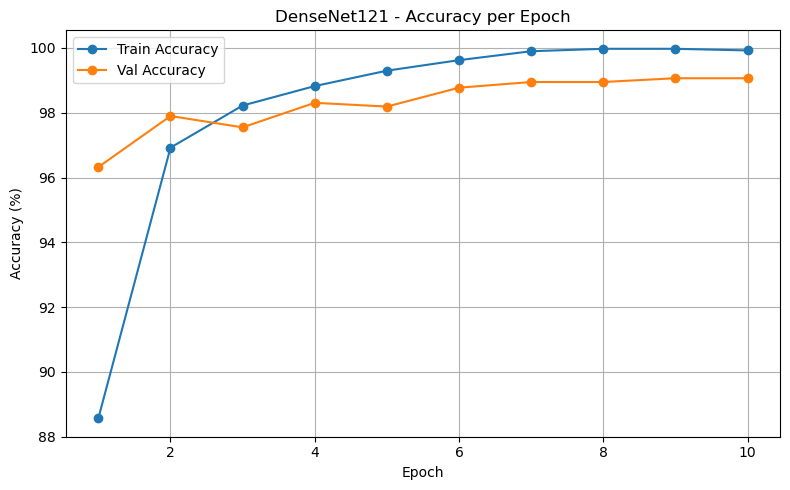

In [16]:
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_accuracies, label='Train Accuracy', marker='o')
plt.plot(epochs, val_accuracies, label='Val Accuracy', marker='o')
plt.title('DenseNet121 - Accuracy per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("densenet121_accuracy_curve.png")
plt.show()

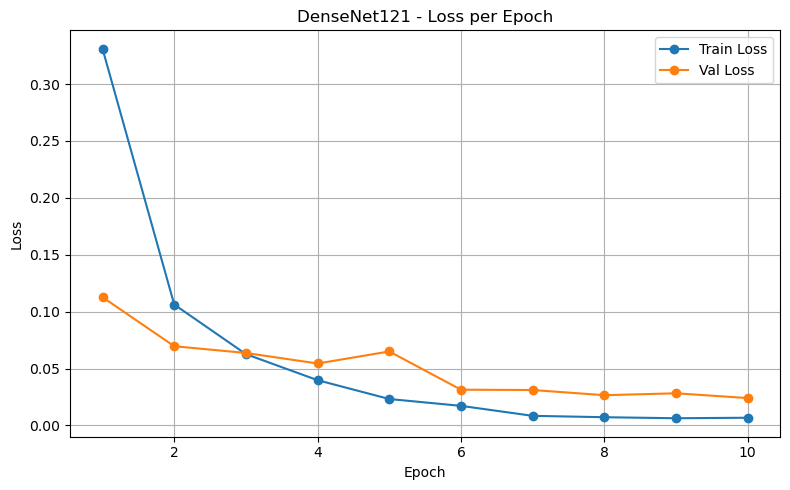

In [17]:
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label='Train Loss', marker='o')
plt.plot(epochs, val_losses, label='Val Loss', marker='o')
plt.title('DenseNet121 - Loss per Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("densenet121_loss_curve.png")
plt.show()

In [18]:
#  Classification Report
print("\n Classification Report:\n")
target_names = full_dataset.classes
print(classification_report(all_labels, all_preds, target_names=target_names))


 Classification Report:

              precision    recall  f1-score   support

      glioma       0.98      1.00      0.99       404
  meningioma       0.99      0.97      0.98       398
     notumor       0.99      1.00      0.99       480
   pituitary       0.99      0.99      0.99       432

    accuracy                           0.99      1714
   macro avg       0.99      0.99      0.99      1714
weighted avg       0.99      0.99      0.99      1714



In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

def plot_confusion_matrix(y_true, y_pred, class_names, title="Confusion Matrix", save_path=None):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.xlabel("Predicted Label")
    plt.ylabel("True Label")
    plt.title(title)
    plt.tight_layout()
    if save_path:
        plt.savefig(save_path)
    plt.show()


In [23]:
import torch
import numpy as np

def unnormalize(img_tensor):
    # Assumes normalization used: Normalize([0.5]*3, [0.5]*3)
    mean = torch.tensor([0.5, 0.5, 0.5])
    std = torch.tensor([0.5, 0.5, 0.5])
    return img_tensor * std[:, None, None] + mean[:, None, None]

def show_classwise_predictions(model, dataset, class_names, device, images_per_class=4):
    model.eval()
    with torch.no_grad():
        for class_idx in range(len(class_names)):
            class_samples = [sample for sample in dataset if sample[1] == class_idx]
            if len(class_samples) < images_per_class:
                continue

            plt.figure(figsize=(12, 4))
            for i in range(images_per_class):
                img, label = class_samples[i]
                input_tensor = img.unsqueeze(0).to(device)
                output = model(input_tensor)
                pred = torch.argmax(output, dim=1).item()

                img = unnormalize(img).permute(1, 2, 0).numpy()
                img = np.clip(img, 0, 1)

                plt.subplot(1, images_per_class, i + 1)
                plt.imshow(img)
                plt.title(f"Pred: {class_names[pred]}\nTrue: {class_names[label]}", fontsize=10)
                plt.axis("off")

            plt.suptitle(f"Class: {class_names[class_idx]}", fontsize=14)
            plt.tight_layout()
            plt.show()


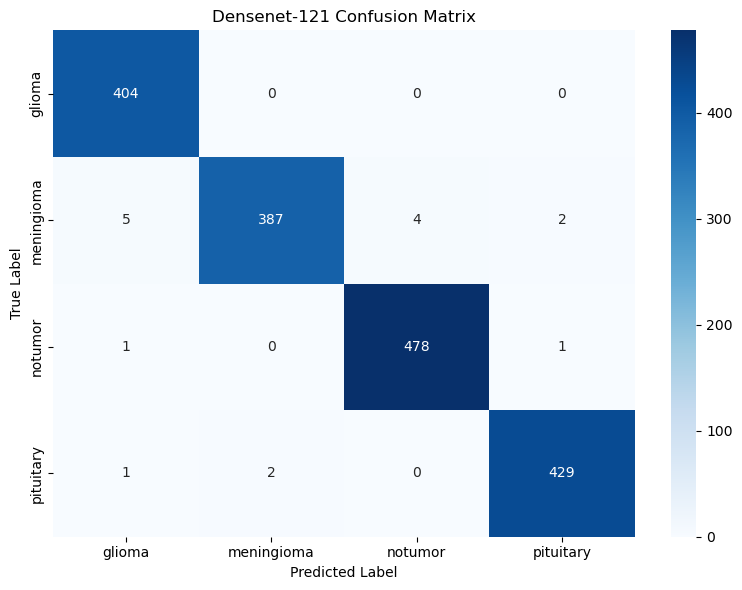

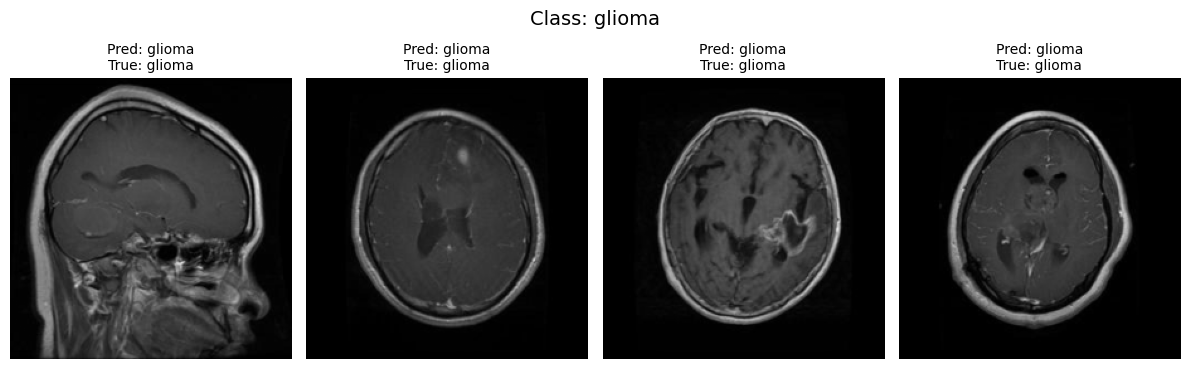

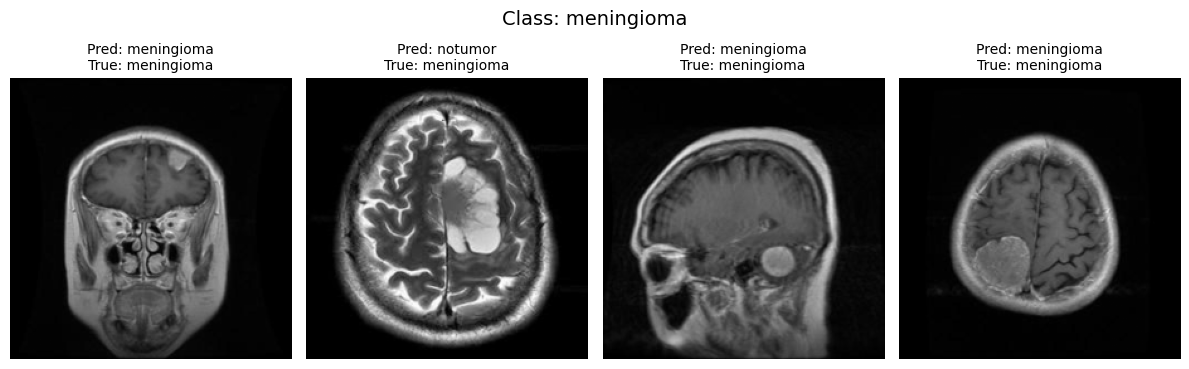

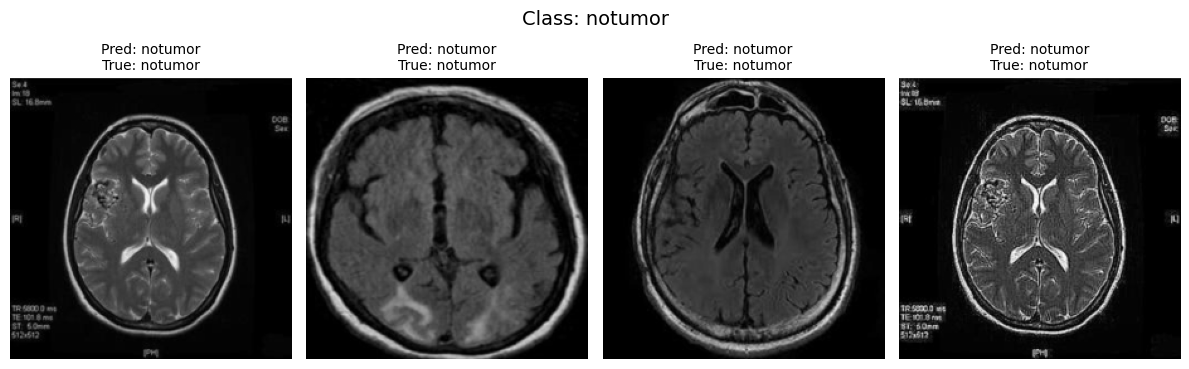

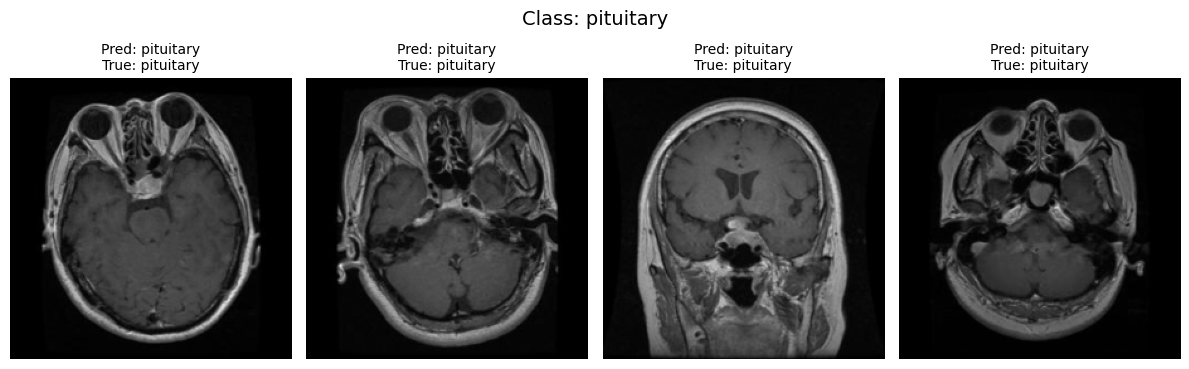

In [24]:
# Call this after training is complete
plot_confusion_matrix(all_labels, all_preds, class_names=full_dataset.classes,
                      title="Densenet-121 Confusion Matrix", save_path="densenet121_confusion_matrix.png")

# Visualize classwise predictions
show_classwise_predictions(model, val_dataset, class_names=full_dataset.classes, device=device, images_per_class=4)

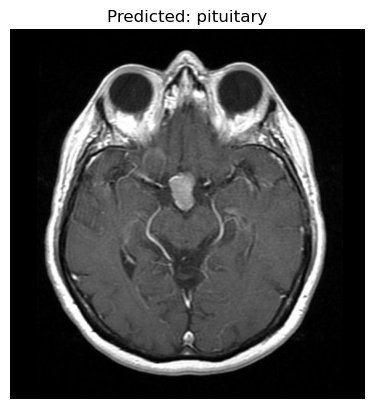

In [32]:
from PIL import Image
import torchvision.transforms as transforms
import torch
import matplotlib.pyplot as plt

#  Transform (same as validation/test transform)
predict_transform = transforms.Compose([
    transforms.Resize((224, 224)),  # DenseNet standard input
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5],
                         [0.5, 0.5, 0.5])
])

#  Prediction function
def predict_image(image_path, model, class_names):
    model.eval()

    image = Image.open(image_path).convert('RGB')
    input_tensor = predict_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(input_tensor)
        _, predicted = torch.max(output, 1)

    # Display image
    plt.imshow(image)
    plt.title(f"Predicted: {class_names[predicted.item()]}")
    plt.axis('off')
    plt.show()

#  Example usage
#test_image_path = r"C:\Users\STUDENT\Downloads\brainmri\archive\Testing_256x256\pituitary\Te-pi_0239.jpg"  # ptuitiary
#test_image_path = r"C:\Users\STUDENT\Downloads\brainmri\archive\Testing_256x256\notumor\Te-no_0238.jpg"  # notumor


#test_image_path = r"C:\Users\STUDENT\Downloads\brain_menin.webp"  # menin

test_image_path = r"C:\Users\STUDENT\Downloads\pitui.jpg"#pituitiary
#test_image_path = r"C:\Users\STUDENT\Downloads\glioma1.png"  # notumor
#test_image_path = r"C:\Users\STUDENT\Downloads\brain_pituitiary.png"#no tumor
predict_image(test_image_path, model, full_dataset.classes)  # 'model' and 'full_dataset' must be from your training notebook
